In [1]:
# Import libraries
import pandas as pd                  # Data Preprocessing
import matplotlib.pyplot as plt      # Data Visualization
import seaborn as sns                # Data Visualization
import missingno as msno             # Missing Data Visualization
from collections import Counter     # Counting

In [9]:
# Load the dataset

path = r"files\retailmart_data.csv"
df = pd.read_csv(path)

In [12]:
df.head()

,Date,Category,Region,Weather,Advertising,Discount,Month,Year,Season,Sales,Customer_Count,Profit
0,2022-01-01,Home Goods,East,Cloudy,1275.18,15.74,January,2022,Winter,2679.56,95,652.90
1,2022-01-02,Electronics,West,Cloudy,1893.89,24.74,January,2022,Winter,3859.05,147,924.16
2,2022-01-02,Apparel,East,Sunny,727.38,8.46,January,2022,Winter,2450.71,79,512.75
3,2022-01-02,Apparel,South,Rainy,1757.23,15.37,January,2022,Winter,3056.75,97,624.60
4,2022-01-05,Home Goods,North,Cloudy,1507.46,16.22,January,2022,Winter,2840.15,116,617.43


In [10]:
df.columns

Index(['Date', 'Category', 'Region', 'Weather', 'Advertising', 'Discount',
       'Month', 'Year', 'Season', 'Sales', 'Customer_Count', 'Profit'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            1000 non-null   object 
 1   Category        1000 non-null   object 
 2   Region          1000 non-null   object 
 3   Weather         1000 non-null   object 
 4   Advertising     1000 non-null   float64
 5   Discount        1000 non-null   float64
 6   Month           1000 non-null   object 
 7   Year            1000 non-null   int64  
 8   Season          1000 non-null   object 
 9   Sales           1000 non-null   float64
 10  Customer_Count  1000 non-null   int64  
 11  Profit          1000 non-null   float64
dtypes: float64(4), int64(2), object(6)
memory usage: 93.9+ KB


In [13]:
# Covert the date column to a pandas datetime object
# df.info() # Date object (string)
df["Date"] = pd.to_datetime(df["Date"])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            1000 non-null   datetime64[ns]
 1   Category        1000 non-null   object        
 2   Region          1000 non-null   object        
 3   Weather         1000 non-null   object        
 4   Advertising     1000 non-null   float64       
 5   Discount        1000 non-null   float64       
 6   Month           1000 non-null   object        
 7   Year            1000 non-null   int64         
 8   Season          1000 non-null   object        
 9   Sales           1000 non-null   float64       
 10  Customer_Count  1000 non-null   int64         
 11  Profit          1000 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(2), object(5)
memory usage: 93.9+ KB


### Sales trend over time for different categories

In [14]:
df["Category"].unique()

array(['Home Goods', 'Electronics', 'Apparel'], dtype=object)

In [26]:
home_goods = df[df["Category"] == "Home Goods"]
electronics = df[df["Category"] == "Electronics"]
apparel = df[df["Category"] == "Apparel"]

df["Category"].unique()

array(['Home Goods', 'Electronics', 'Apparel'], dtype=object)

In [20]:
def calculate():
    return 100, 50

revenue, cost = calculate()

print(revenue)  # 100
print(cost)     # 50


a, b = 10, 20

print(a)  # 10
print(b)  # 20

100
50
10
20


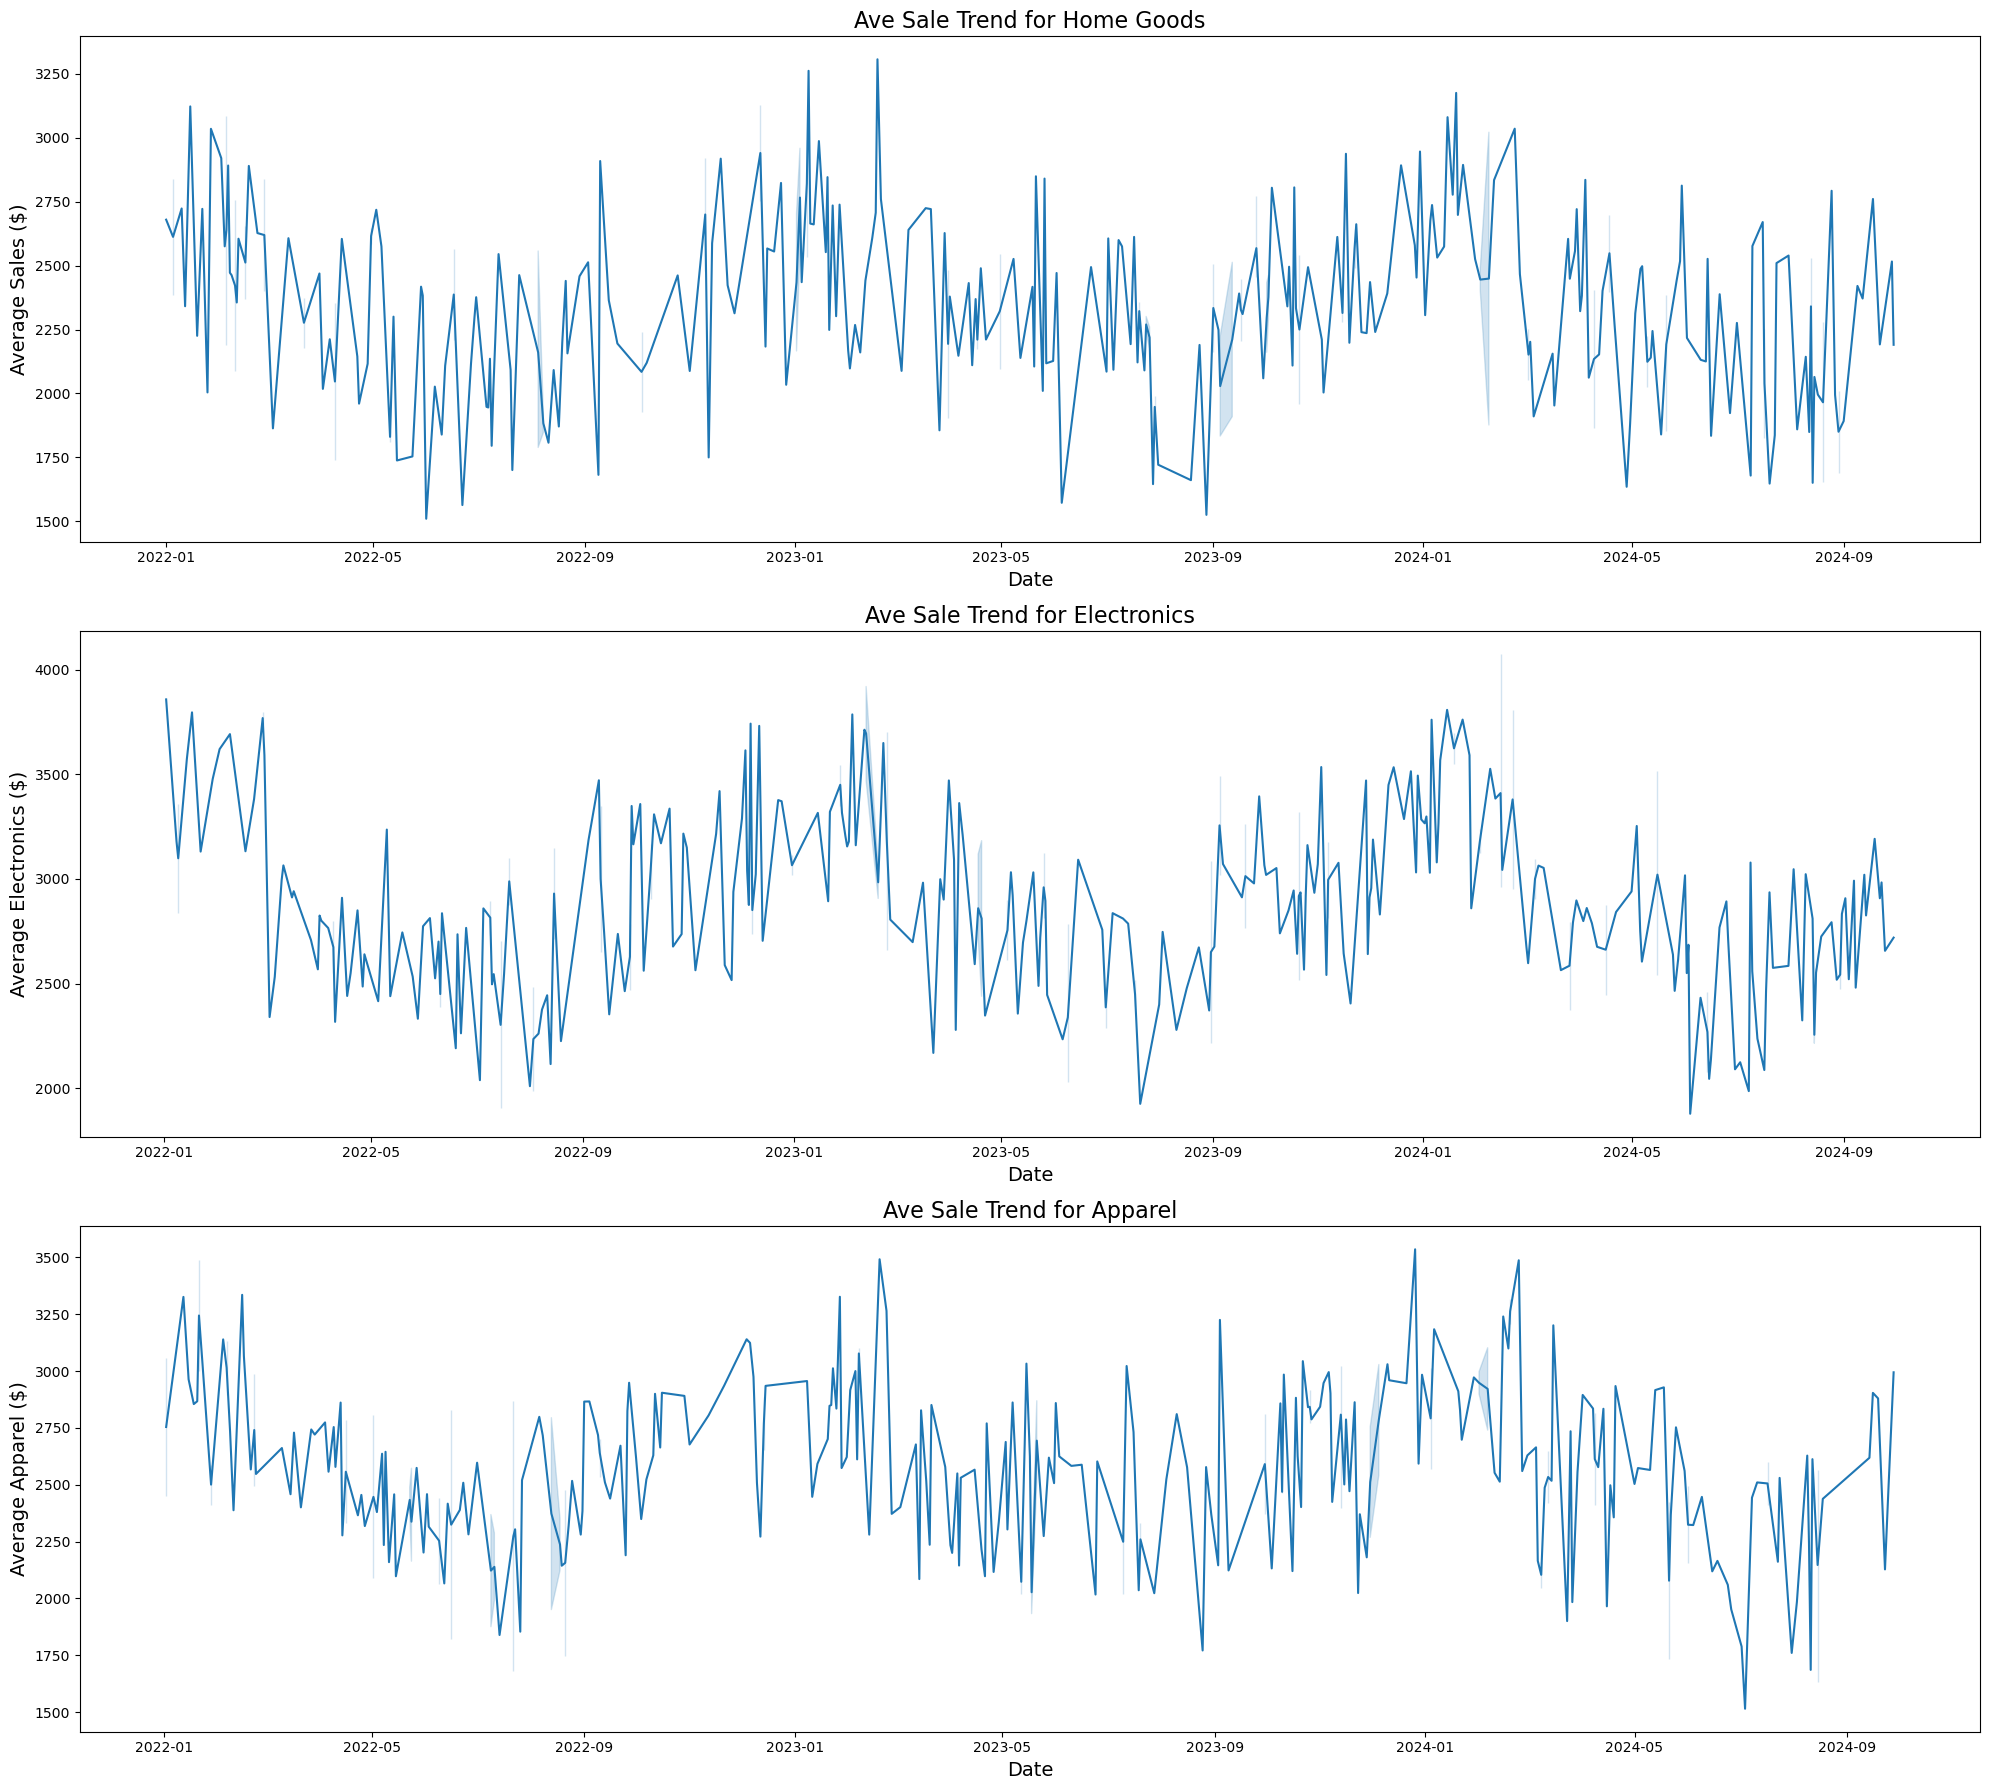

In [27]:
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(20, 18))

sns.lineplot(x="Date", y="Sales", data=home_goods, ax=ax[0])
ax[0].set_title("Ave Sale Trend for Home Goods", fontsize=16)
ax[0].set_xlabel("Date", fontsize=14)
ax[0].set_ylabel("Average Sales ($)", fontsize=14)

sns.lineplot(x="Date", y="Sales", data=electronics, ax=ax[1])
ax[1].set_title("Ave Sale Trend for Electronics", fontsize=16)
ax[1].set_xlabel("Date", fontsize=14)
ax[1].set_ylabel("Average Electronics ($)", fontsize=14)

sns.lineplot(x="Date", y="Sales", data=apparel, ax=ax[2])
ax[2].set_title("Ave Sale Trend for Apparel", fontsize=16)
ax[2].set_xlabel("Date", fontsize=14)
ax[2].set_ylabel("Average Apparel ($)", fontsize=14)

plt.tight_layout()
plt.show()

### Insight: There are seasonal spikes during December-January and then dips in the summer months

### Visualize this seasonality across monthly sales

In [30]:
df['Year_Month'] = df["Date"].dt.to_period("M").astype(str)
df["Year_Month"]

0      2022-01
1      2022-01
2      2022-01
3      2022-01
4      2022-01
        ...   
995    2024-09
996    2024-09
997    2024-09
998    2024-09
999    2024-09
Name: Year_Month, Length: 1000, dtype: object

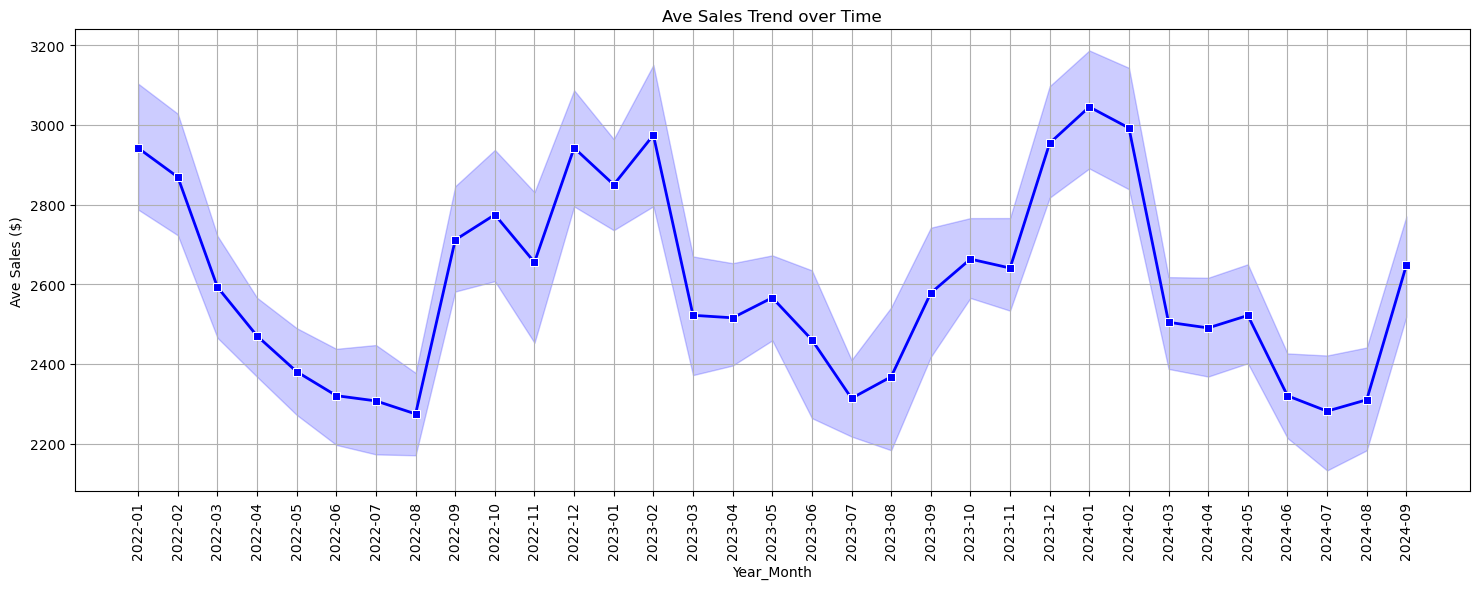

In [36]:
plt.figure(figsize=(18,6))

sns.lineplot(x="Year_Month", y="Sales", data=df, color="blue", marker="s", linewidth=2)
plt.title("Ave Sales Trend over Time")
plt.xlabel("Year_Month")
plt.ylabel("Ave Sales ($)")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

### Insight: Average Sales Trend Over Time (2022–2024)

- Fluctuating sales performance: Average monthly sales show noticeable fluctuations, with no consistent upward or downward trend across the period.
- Peak sales: January 2024 recorded the highest average sales at approximately $3,050, followed by February 2024 and December 2023.
- Lowest sales: August 2022 recorded the lowest average sales at approximately $2,275, with another significant decline around July 2024.
- Possible seasonal pattern: Sales generally increased towards the end of 2022 and 2023, followed by a decline during the middle months of the year. However, more historical data is needed to confirm seasonality.

Overall Insight: Average sales appear stronger around the end and beginning of the year, while mid-year performance tends to be weaker. This suggests an opportunity to investigate seasonal demand and develop targeted strategies to improve sales during slower months.

### Lets confirm this trend by plotting the average monthly sales across different seasons

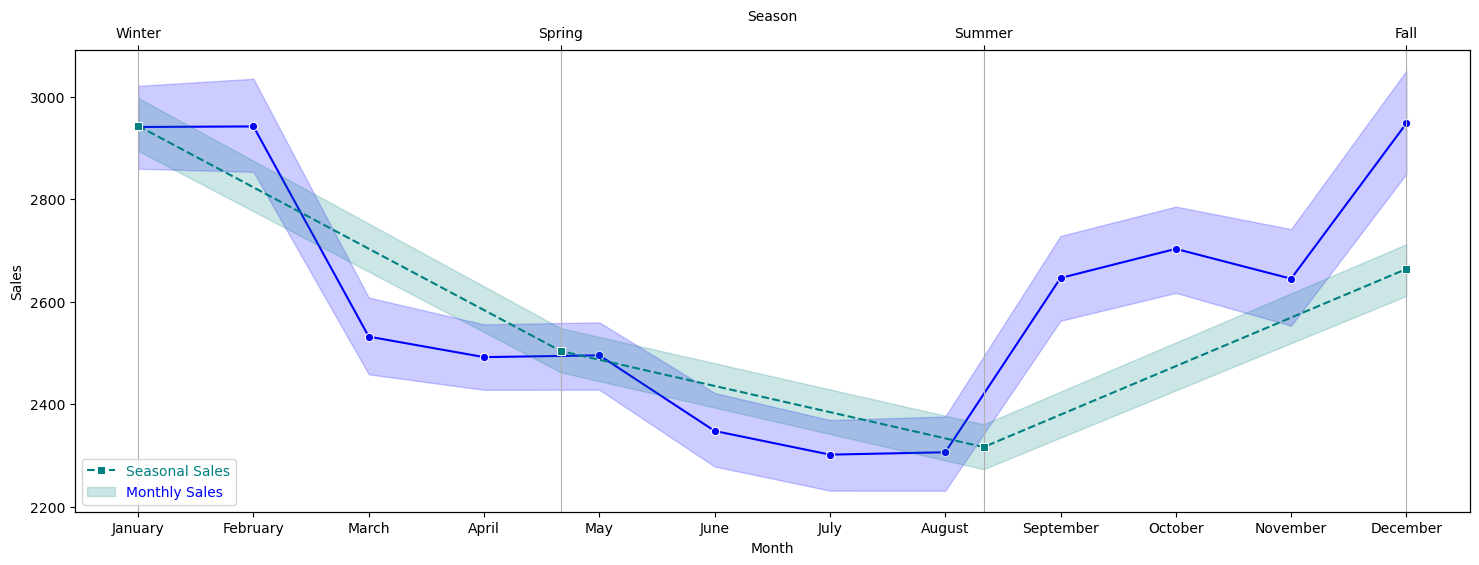

In [40]:
fig, ax = plt.subplots(figsize=(18,6))

sns.lineplot(x="Month", y="Sales", data=df, color="blue", marker="o")
ax2 = ax.twiny()
sns.lineplot(x="Season", y="Sales", data=df, color="teal", marker="s", linestyle="--")

plt.legend(labels=["Seasonal Sales", "Monthly Sales"], loc="lower left", labelcolor=["teal", "blue"])
plt.grid(True)
plt.show()

### Insight: Seasonal Sales Trend

- Winter records the highest sales, particularly in January and February, with average sales reaching approximately $2,950.
- Sales decline during spring, falling from around $2,530 in March to $2,350 by June.
- Summer experiences the lowest sales, especially in July and August, averaging approximately $2,300.
- Sales recover during fall, with a steady increase from September through December, suggesting stronger year-end demand.

Overall Insight: Sales demonstrate a clear seasonal pattern, with stronger performance in winter and towards year-end, while summer records the weakest performance. This suggests opportunities for targeted summer promotions and better inventory planning ahead of peak sales periods.

### Customer Activity Analysis

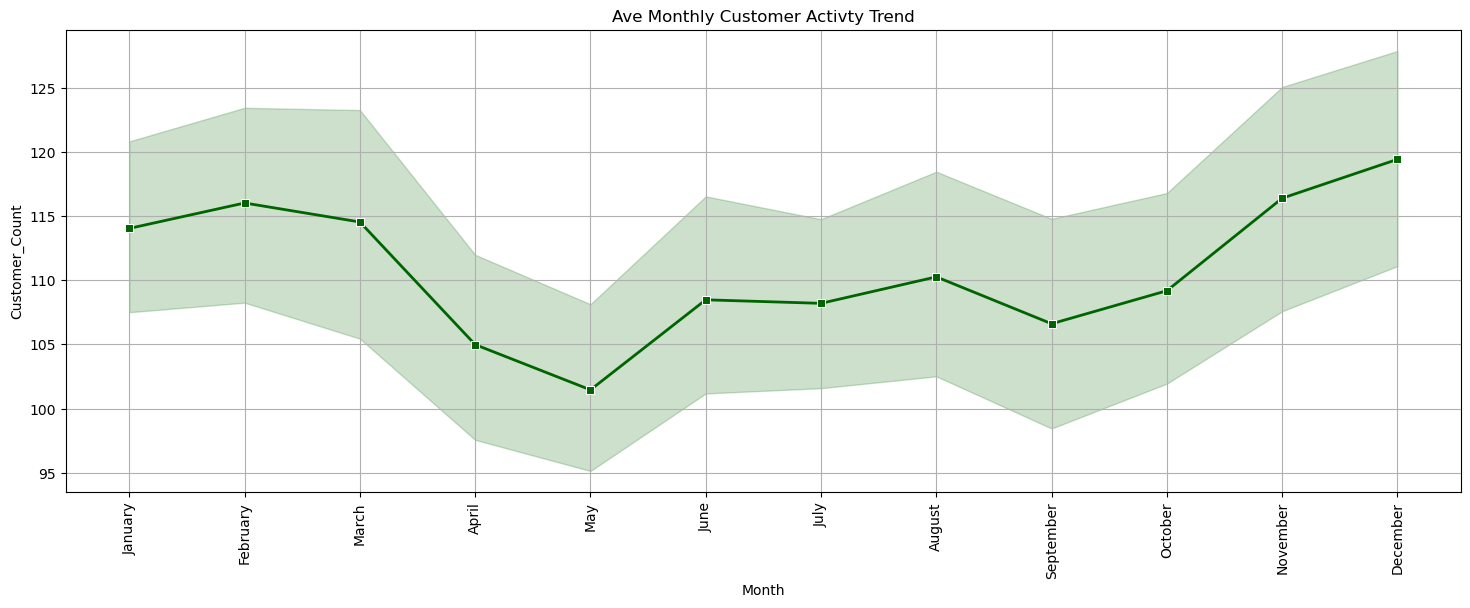

In [43]:
# Monthly Customer Trend Analysis
plt.figure(figsize=(18,6))

sns.lineplot(x="Month", y="Customer_Count", data=df, color="darkgreen", marker="s", linewidth=2)
plt.title("Ave Monthly Customer Activty Trend")
# plt.xlabel("Year_Month")
# plt.ylabel("Ave Sales ($)")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

### Insight: Average Monthly Customer Activity Trend

- Strong early-year activity: Customer activity remains relatively high from January to March, peaking at approximately 116 customers in February.
- Lowest customer activity: May records the lowest average customer count at around 101, following a noticeable decline in April.
- Mid-year recovery: Customer activity gradually improves between June and August, before experiencing a slight decline in September.
- Strong year-end growth: Activity increases significantly from October to December, reaching its highest level of approximately 119 customers in December.

Overall Insight: Customer activity fluctuates throughout the year, with stronger engagement at the beginning and end of the year and weaker activity during spring. This suggests opportunities for targeted customer engagement campaigns during slower months and improved resource planning ahead of year-end demand.

### The same analysis over the entire timeline

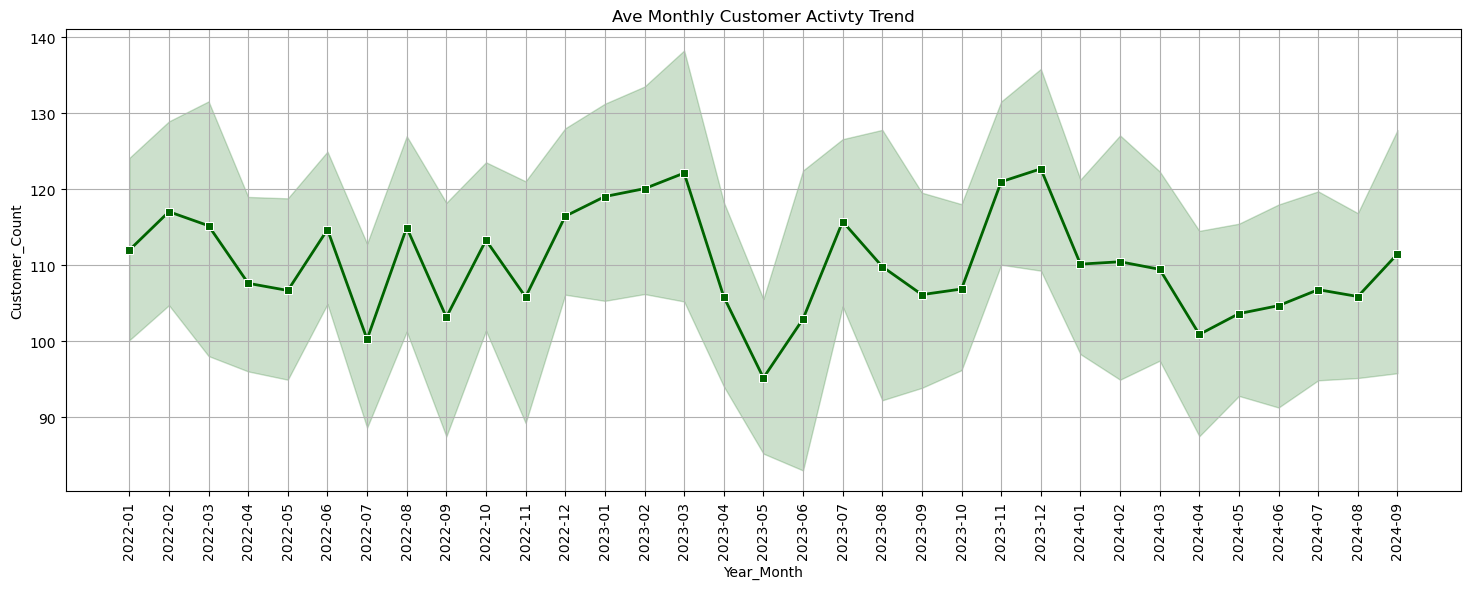

In [44]:
# Monthly Customer Trend Analysis
plt.figure(figsize=(18,6))

sns.lineplot(x="Year_Month", y="Customer_Count", data=df, color="darkgreen", marker="s", linewidth=2)
plt.title("Ave Monthly Customer Activty Trend")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

### Insight: Average Monthly Customer Activity Trend (2022–2024)

- Fluctuating customer activity: Customer counts vary considerably throughout the period, with no consistent upward or downward trend.
- Peak customer activity: December 2023 records the highest average customer count at approximately 123, followed by March 2023 (122) and November 2023 (121).
- Lowest customer activity: May 2023 records the lowest average customer count at approximately 95, followed by July 2022 and April 2024.
- Strongest performance in 2023: Customer activity reached several peaks during 2023, particularly in the first quarter and towards year-end.
- Moderate activity in 2024: Customer counts remained relatively stable between April and September 2024, generally ranging from 101 to 112.

Overall Insight: Customer activity shows noticeable monthly fluctuations, with particularly strong performance towards the end of 2023. The sharp decline in May 2023 suggests a period worth investigating, while the relatively stable activity in 2024 highlights opportunities to improve customer engagement and retention.

### Analyze the Advert

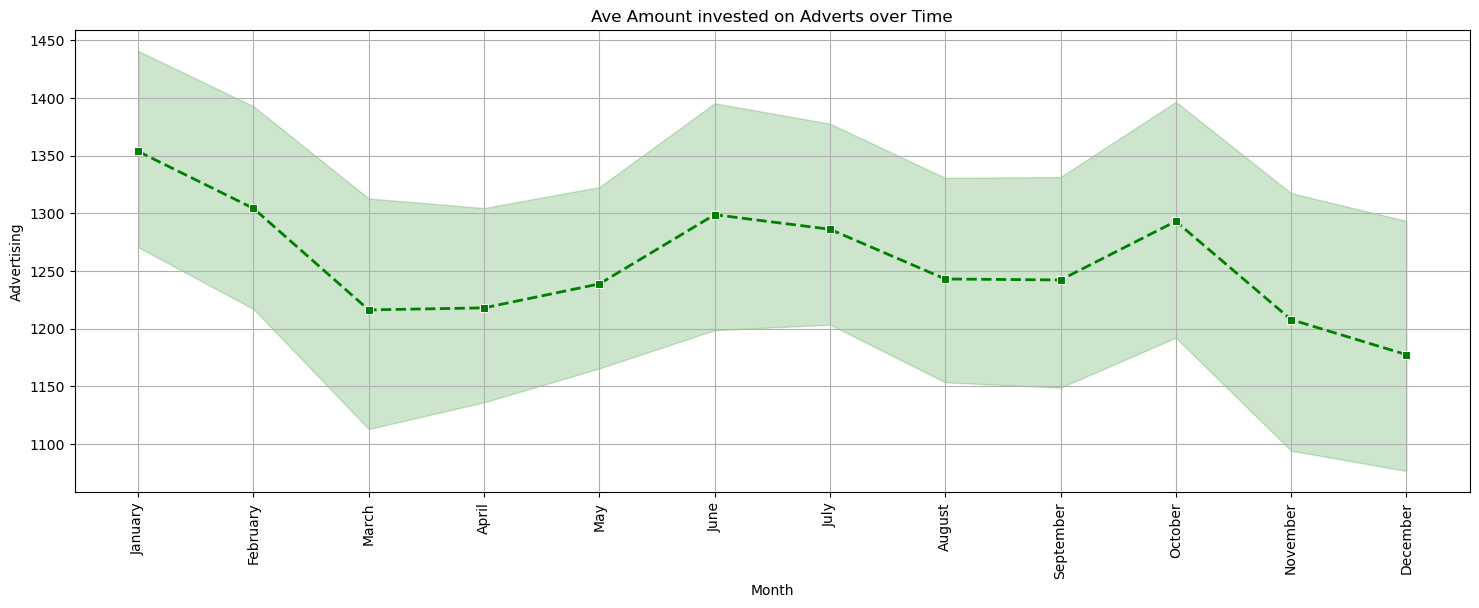

In [47]:
# Investigate the reason for the above using the amount invested
plt.figure(figsize=(18,6))

sns.lineplot(x="Month", y="Advertising", data=df, color="green", marker="s", linestyle="--", linewidth=2)
plt.title("Ave Amount invested on Adverts over Time")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

### Insight: Average Advertising Expenditure Over Time

- Highest advertising investment: January records the highest average advertising expenditure at approximately $1,350, followed by February ($1,305).
- Decline in spring: Advertising spending drops significantly between January and March, reaching approximately $1,215, before gradually recovering in May.
- Mid-year recovery: Investment increases to approximately $1,300 in June, followed by a gradual decline between July and September.
- Temporary increase in October: Advertising expenditure rises to approximately $1,295 before declining sharply towards year-end.
- Lowest advertising investment: December records the lowest average expenditure at approximately $1,175.

Overall Insight: Advertising expenditure fluctuates throughout the year, with higher investment at the beginning of the year and during June and October. Interestingly, customer activity remains relatively strong towards year-end despite declining advertising expenditure. This suggests that seasonal demand, customer loyalty or other factors may influence customer engagement beyond advertising spending.

Recommendation: Investigate the relationship between advertising expenditure and customer activity to assess marketing effectiveness and identify opportunities to optimise advertising budgets during periods of lower customer engagement.

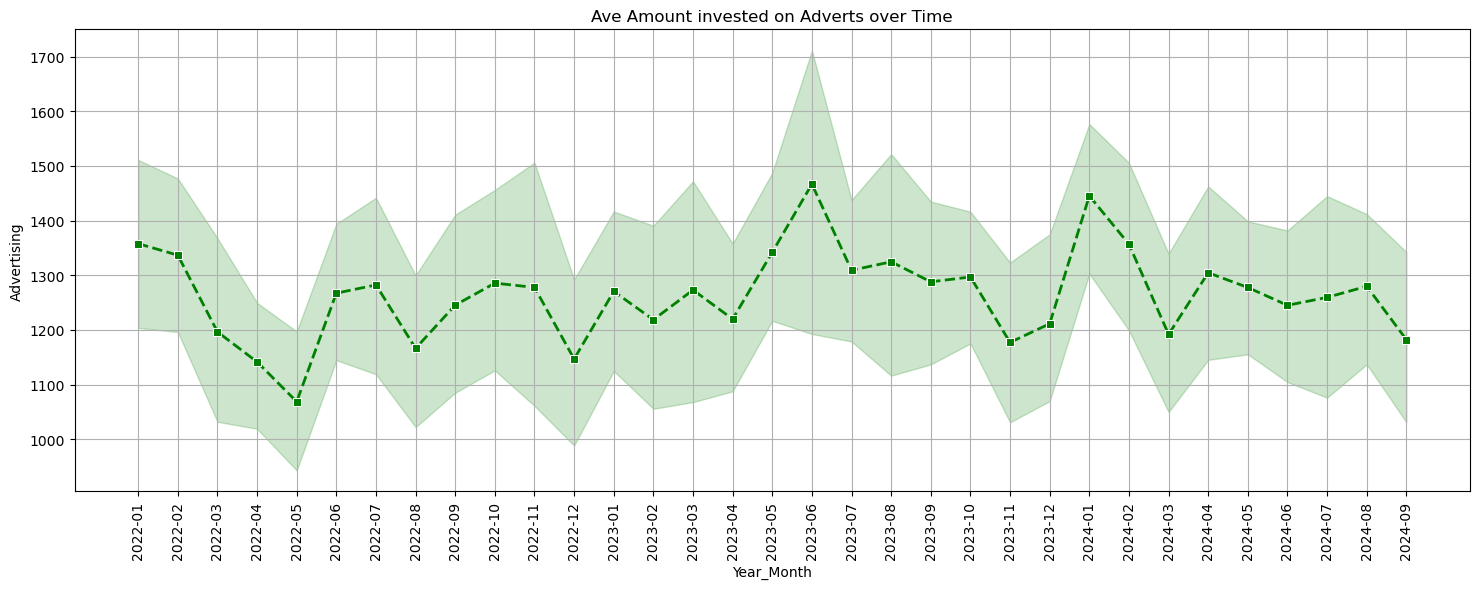

In [49]:
# Investigate the reason for the above using the amount invested
plt.figure(figsize=(18,6))

sns.lineplot(x="Year_Month", y="Advertising", data=df, color="green", marker="s", linestyle="--", linewidth=2)
plt.title("Ave Amount invested on Adverts over Time")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

### Insight: Average Advertising Expenditure Over Time (2022–2024)

- Fluctuating advertising expenditure: Advertising investment varies considerably throughout the period, with no consistent upward or downward trend.
- Highest advertising investment: June 2023 records the highest average expenditure at approximately $1,465, followed by January 2024 ($1,445).
- Lowest advertising investment: May 2022 records the lowest average expenditure at approximately $1,070, followed by December 2022 ($1,150).
- Advertising fluctuations in 2023: Spending increases significantly between April and June before declining in July, with moderate fluctuations throughout the remaining months.
- Moderate investment in 2024: Following a peak in January, advertising expenditure generally declines and fluctuates between approximately $1,180 and $1,310 from March to September.

Overall Insight: Advertising expenditure shows substantial monthly fluctuations without a sustained growth trend. Interestingly, the highest advertising investment in June 2023 does not coincide with the highest customer activity, which occurred in December 2023. This suggests that increased advertising expenditure does not necessarily translate into immediate customer engagement.

Recommendation: Compare advertising expenditure with customer activity and sales performance at the same monthly level, including possible delayed effects, to evaluate advertising effectiveness and identify periods where marketing investment generates stronger returns.

### Average Advertising and Sales Trend Over Time

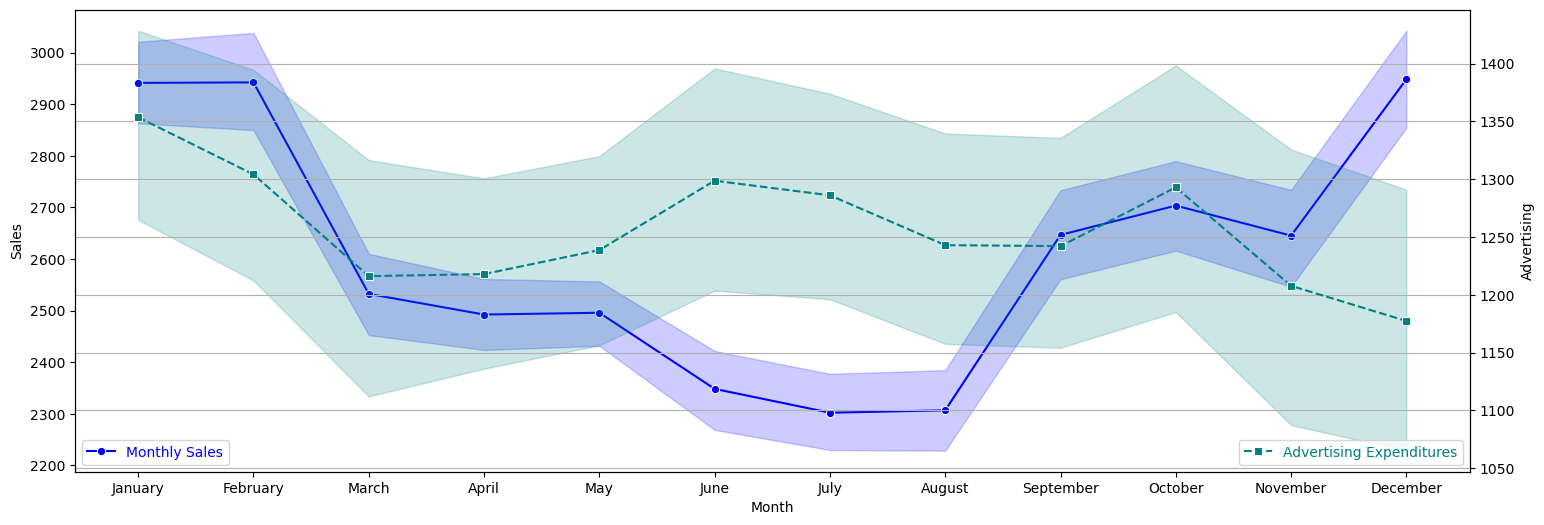

In [59]:
fig, ax = plt.subplots(figsize=(18,6))

sns.lineplot(x="Month", y="Sales", data=df, color="blue", marker="o", ax=ax)
ax.legend(labels=["Monthly Sales"], loc="lower left", labelcolor=["blue"])

ax2 = ax.twinx()

sns.lineplot(x="Month", y="Advertising", data=df, color="teal", marker="s", linestyle="--", ax=ax2)
ax2.legend(labels=["Advertising Expenditures"], loc="lower right", labelcolor=["teal",])

plt.grid(True)
plt.show()

### Final Insight: Average Monthly Sales vs Advertising Expenditure

- January–February: High sales coincide with relatively high advertising expenditure.
- March–April: Both metrics decline, suggesting a possible positive relationship.
- June–August: Advertising expenditure remains relatively high while sales fall to their lowest levels, indicating a weak or delayed relationship.
- September–October: Both metrics increase, suggesting improved sales performance alongside higher advertising investment.
- November–December: Sales recover sharply in December despite declining advertising expenditure, suggesting stronger seasonal demand or other influencing factors.

Overall Insight: Advertising expenditure and sales demonstrate an inconsistent relationship. While higher advertising investment coincides with stronger sales in some months, the significant year-end sales increase despite lower advertising expenditure suggests that seasonal demand and other factors may play a more important role.

Recommendation: Evaluate advertising effectiveness using campaign-level performance, return on advertising spend (ROAS), and lagged correlation analysis to determine whether advertising investment contributes to sales growth.

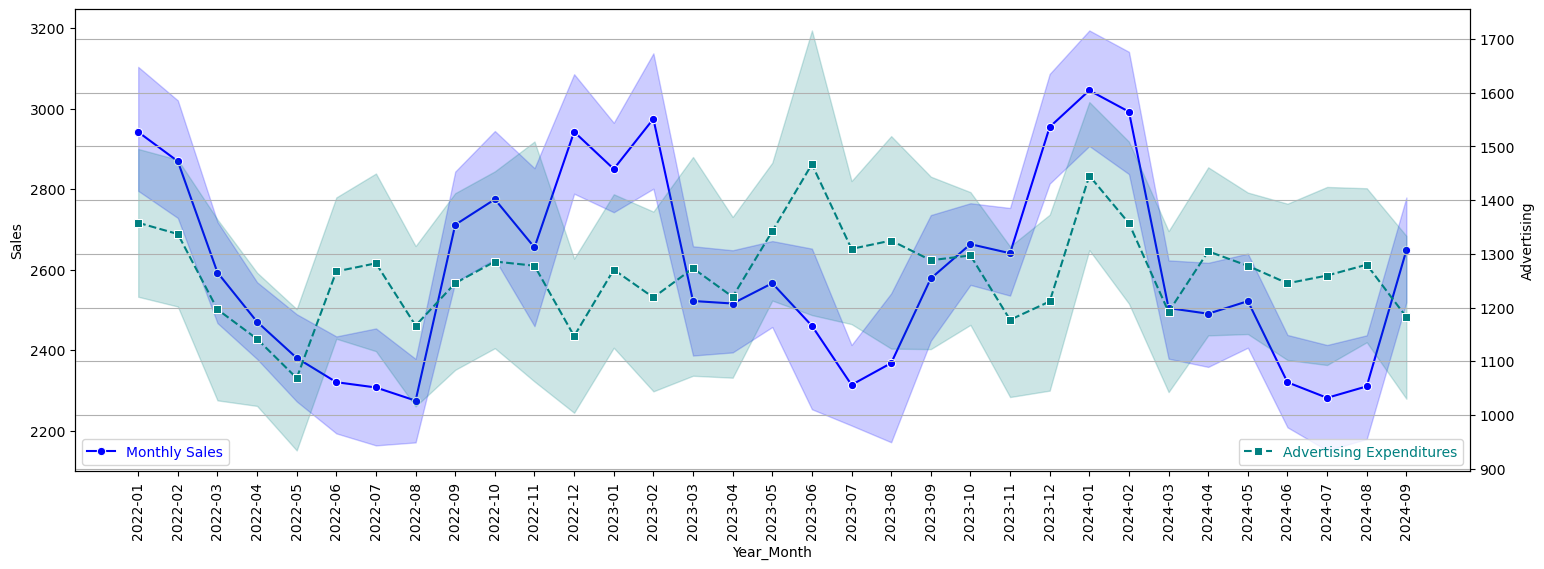

In [63]:
fig, ax = plt.subplots(figsize=(18,6))

sns.lineplot(x="Year_Month", y="Sales", data=df, color="blue", marker="o", ax=ax)
ax.legend(labels=["Monthly Sales"], loc="lower left", labelcolor=["blue"])
plt.xticks(rotation=90)

ax2 = ax.twinx()

sns.lineplot(x="Year_Month", y="Advertising", data=df, color="teal", marker="s", linestyle="--", ax=ax2)
ax2.legend(labels=["Advertising Expenditures"], loc="lower right", labelcolor=["teal",])


plt.grid(True)
plt.show()

### Insight: Average Monthly Sales vs Advertising Expenditure (2022–2024)

- Fluctuating performance: Both sales and advertising expenditure vary considerably throughout the period, with no consistent positive relationship.
- Strong sales performance: January 2024 records the highest average sales at approximately $3,050, alongside relatively high advertising expenditure of $1,440.
- Lowest sales: August 2022 records the lowest average sales at approximately $2,275, following a decline in advertising expenditure earlier in the year.
- Advertising peaks without corresponding sales growth: June 2023 records the highest advertising expenditure at approximately $1,470, while average sales remain relatively low at $2,460.
- Year-end sales recovery: Sales increase significantly in December 2022 and December 2023, despite advertising expenditure remaining moderate or relatively low.
- 2024 performance: Sales decline sharply after February 2024, with both sales and advertising expenditure fluctuating throughout the subsequent months.

Overall Insight: Advertising expenditure does not consistently align with sales performance. While higher advertising investment coincides with stronger sales in some periods, the strong year-end sales performance and weaker sales during certain high-spending months suggest that seasonal demand and other factors may influence sales more significantly.

Recommendation: Investigate advertising effectiveness through monthly correlation analysis, lagged relationships and return on advertising spend (ROAS). This could help determine whether advertising investment contributes to sales growth and identify opportunities to optimise marketing expenditure.

### Discount Analysis Over Time

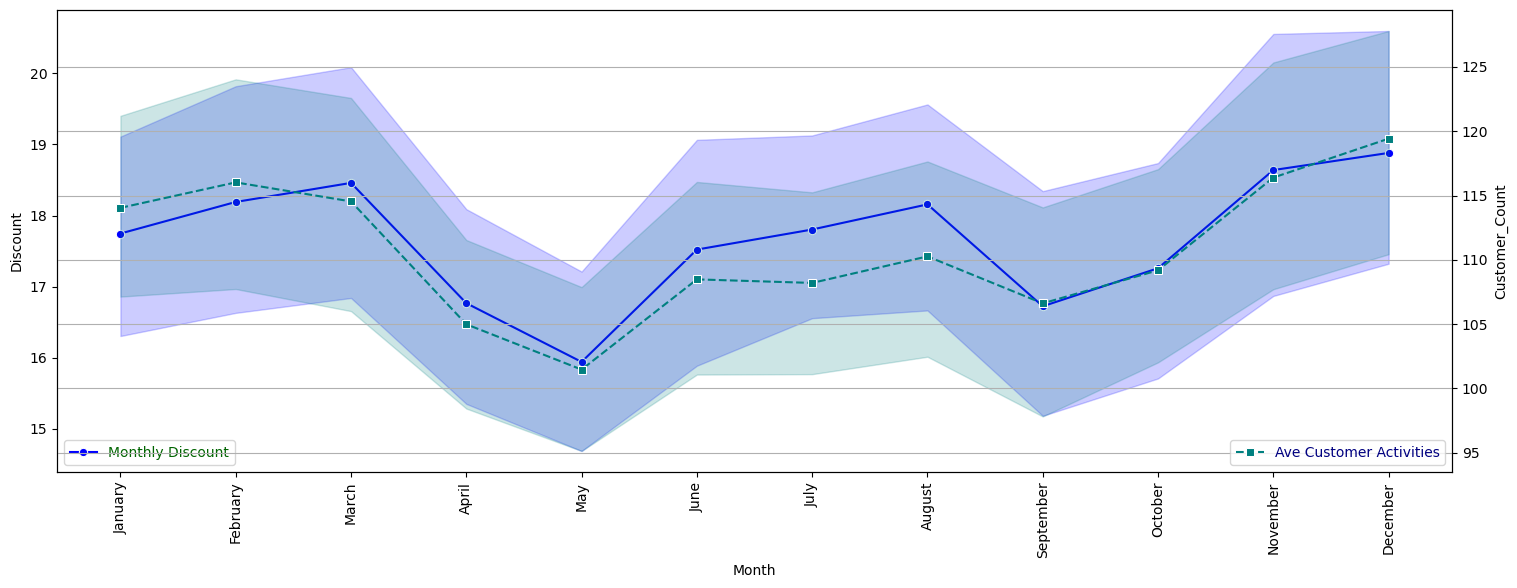

In [65]:
# Does Discount attract more customer?

fig, ax = plt.subplots(figsize=(18,6))

sns.lineplot(x="Month", y="Discount", data=df, color="blue", marker="o", ax=ax)
ax.legend(labels=["Monthly Discount"], loc="lower left", labelcolor=["darkgreen"])
plt.xticks(rotation=90)

ax2 = ax.twinx()

sns.lineplot(x="Month", y="Customer_Count", data=df, color="teal", marker="s", linestyle="--", ax=ax2)
ax2.legend(labels=["Ave Customer Activities"], loc="lower right", labelcolor=["navy",])


plt.grid(True)
plt.show()

### Insight: Average Monthly Discount vs Customer Activity

- Strong positive relationship: Discounts and customer activity follow very similar patterns throughout the year, suggesting that higher discounts may be associated with increased customer engagement.
- Spring decline: Both metrics decrease significantly between March and May, with May recording the lowest average discount (approximately 15.9) and customer activity (approximately 101).
- Mid-year recovery: Discounts increase between June and August, accompanied by a recovery in customer activity, suggesting a possible positive response to promotional incentives.
- September decline: Both discounts and customer activity decline in September before recovering towards year-end.
- Strong year-end performance: November and December record higher discounts and customer activity, with December reaching approximately 18.9 in discounts and 119 customers.

Overall Insight: The close alignment between discounts and customer activity suggests a positive association. Higher discounts generally coincide with increased customer engagement, particularly towards year-end. However, this does not establish that discounts are causing the increase, as seasonal demand and other factors may also contribute.

Recommendation: Investigate the correlation between discounts and customer activity, then compare discount levels against sales revenue and profit margins to determine whether promotional incentives are generating profitable growth.

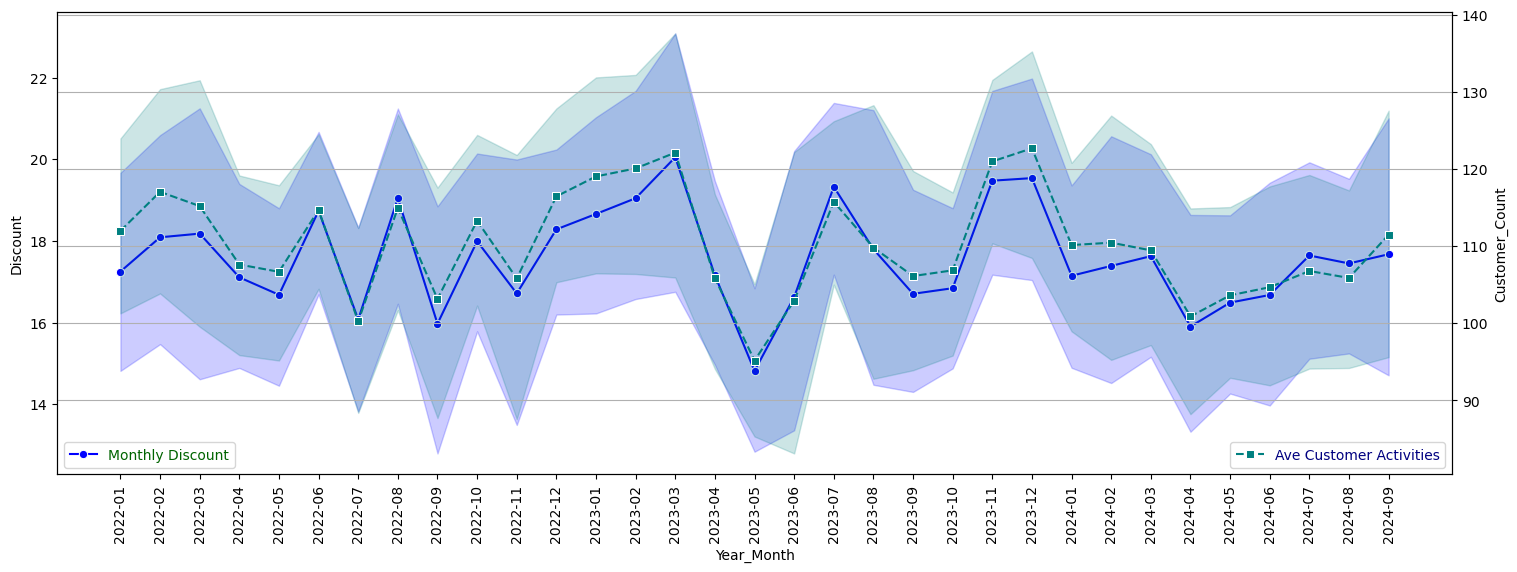

In [66]:
# Does Discount attract more customer?

fig, ax = plt.subplots(figsize=(18,6))

sns.lineplot(x="Year_Month", y="Discount", data=df, color="blue", marker="o", ax=ax)
ax.legend(labels=["Monthly Discount"], loc="lower left", labelcolor=["darkgreen"])
plt.xticks(rotation=90)

ax2 = ax.twinx()

sns.lineplot(x="Year_Month", y="Customer_Count", data=df, color="teal", marker="s", linestyle="--", ax=ax2)
ax2.legend(labels=["Ave Customer Activities"], loc="lower right", labelcolor=["navy",])


plt.grid(True)
plt.show()

### Higher discount, More Customers

### Insight: Monthly Discount vs Customer Activity (2022–2024)

- Strong alignment: Discounts and customer activity follow closely similar patterns across most months, suggesting a positive relationship between promotional discounts and customer engagement.
- Peak performance: March 2023 records the highest average discount (approximately 20%), alongside high customer activity of approximately 122.
- Lowest performance: May 2023 records the lowest average discount (approximately 14.8%) and customer activity (approximately 95), reinforcing the observed positive association.
- Year-end recovery: Both discounts and customer activity increase towards the end of 2022 and 2023, suggesting that promotional activities may coincide with stronger customer engagement.
- 2024 performance: Both metrics decline sharply in April before gradually recovering, although customer activity remains relatively moderate through September.

Overall Insight: Discounts and customer activity show a consistent positive association across the observed period. Months with higher average discounts generally record higher customer activity, suggesting that promotional incentives may be linked to customer engagement.

Recommendation: Further investigate whether increased discounts translate into higher sales revenue and profit, rather than simply attracting more customers. Comparing discount levels with profit margins and transaction volumes would help determine whether the promotional strategy is financially sustainable.



### Average Sales by Region

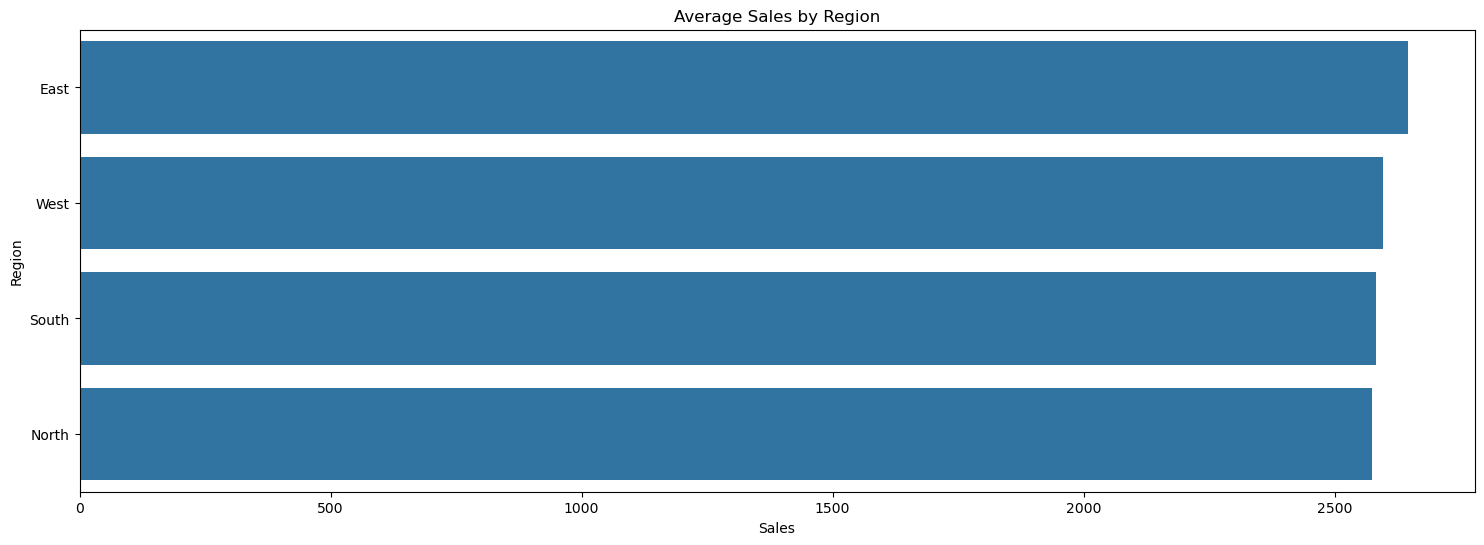

In [67]:
fig, ax = plt.subplots(figsize=(18,6))

sns.barplot(x="Sales", y="Region", data=df, orient="h", errorbar=None)
plt.title("Average Sales by Region")
plt.show()

### Insight: Average Sales by Region

- East leads in average sales, recording approximately $2,650, making it the highest-performing region.
- West follows closely, with average sales of approximately $2,600, indicating strong regional performance.
- South records slightly lower sales, averaging around $2,590, but remains competitive with the other regions.
- North has the lowest average sales, at approximately $2,570, although the difference is relatively small.

Overall Insight: Average sales are fairly consistent across all four regions, with the East performing slightly better than the others. This suggests a relatively balanced regional sales distribution, without significant disparities in average transaction value.

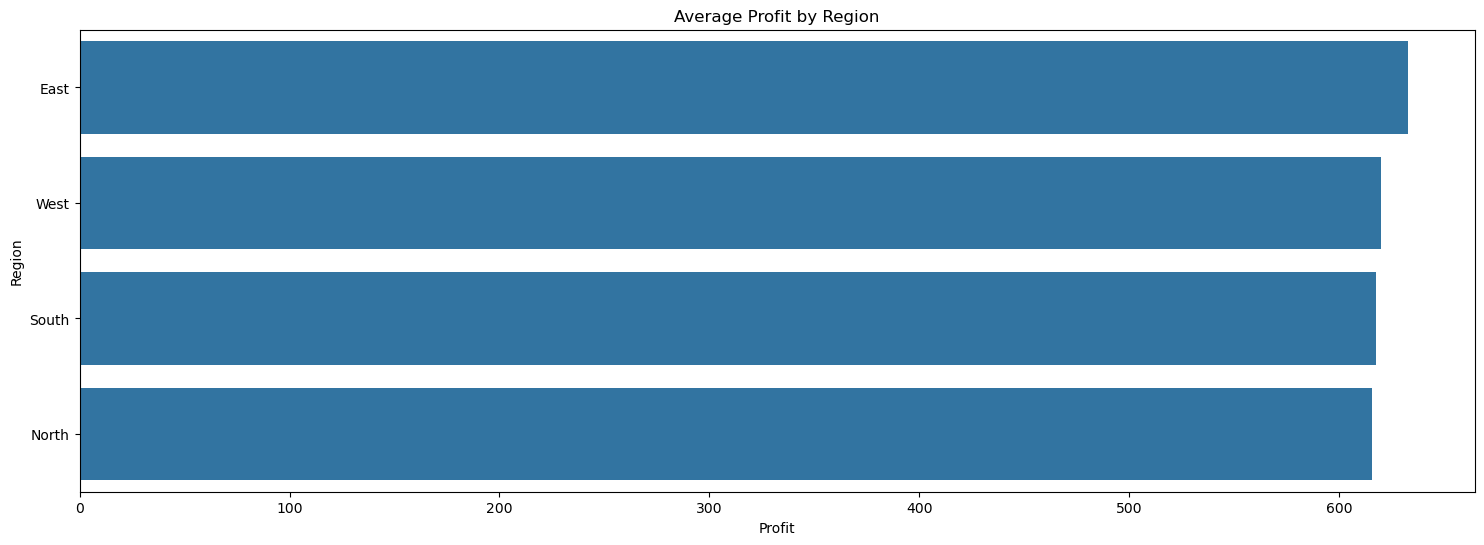

In [68]:
fig, ax = plt.subplots(figsize=(18,6))

sns.barplot(x="Profit", y="Region", data=df, orient="h", errorbar=None)
plt.title("Average Profit by Region")
plt.show()

### Insight: Average Profit by Region

- East leads in profitability, recording the highest average profit at approximately $635, consistent with its leading position in average sales.
- West follows closely, with an average profit of approximately $620, indicating strong financial performance.
- South records slightly lower profitability, averaging around $618, but remains competitive with the other regions.
- North has the lowest average profit, at approximately $615, although the difference between regions is relatively small.

Overall Insight: Average profitability is fairly consistent across all four regions, with the East performing slightly better. This closely mirrors the regional sales trend, suggesting that regions generating higher average sales also tend to achieve higher average profits.

Recommendation: Investigate regional profit margins, transaction volumes, operating costs and discount levels to determine which regions are most efficient at converting sales into profit. This could help identify opportunities to improve profitability in the North and other regions.

### Average Sales by Catergory

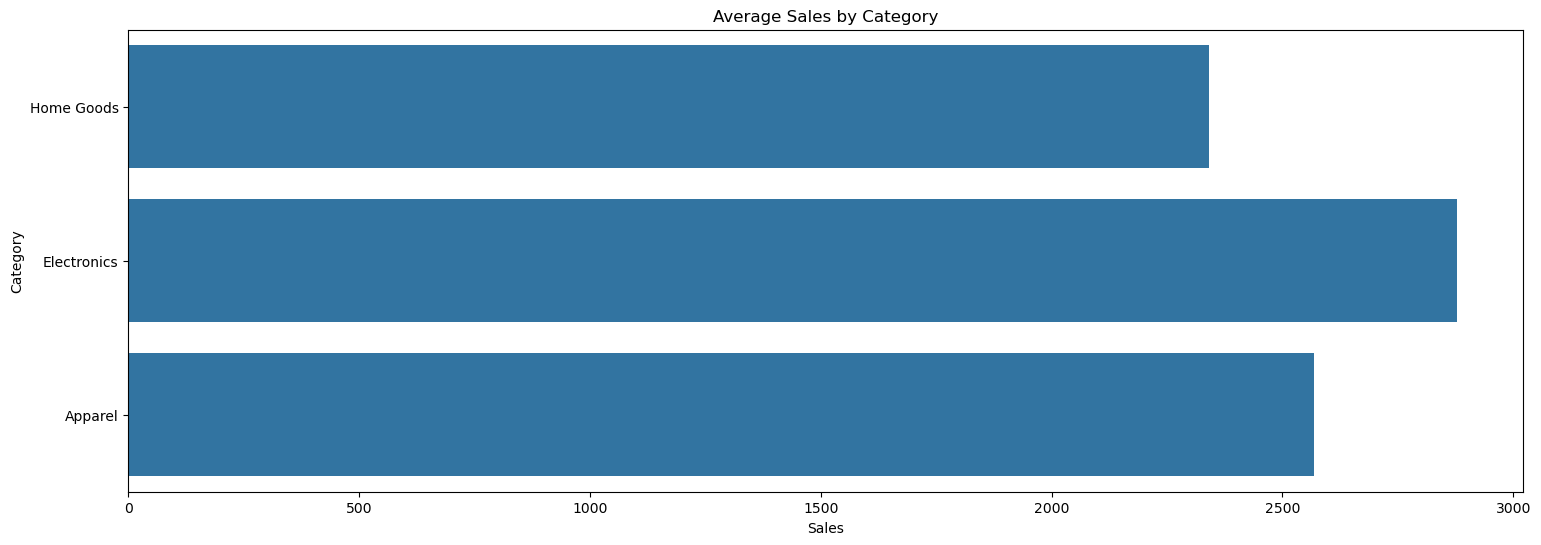

In [70]:
fig, ax = plt.subplots(figsize=(18,6))

sns.barplot(x="Sales", y="Category", data=df, orient="h", errorbar=None)
plt.title("Average Sales by Category")
plt.show()

### Insight: Average Sales by Product Category

- Electronics leads in average sales, recording approximately $2,880, making it the highest-performing product category.
- Apparel ranks second, with average sales of approximately $2,570, indicating relatively strong performance.
- Home Goods records the lowest average sales, at approximately $2,340, suggesting lower average transaction values compared with the other categories.
- Sales variation: Electronics outperforms Home Goods by approximately $540 in average sales, indicating a noticeable difference in transaction values across categories.

Overall Insight: Electronics generates the highest average sales, followed by Apparel and Home Goods. This suggests that Electronics products typically generate higher transaction values, potentially due to higher product prices or purchasing patterns.

Recommendation: Investigate total revenue, transaction volumes, profit margins and discount levels across product categories to determine whether Electronics also contributes the most to overall profitability and identify opportunities to improve Home Goods performance.

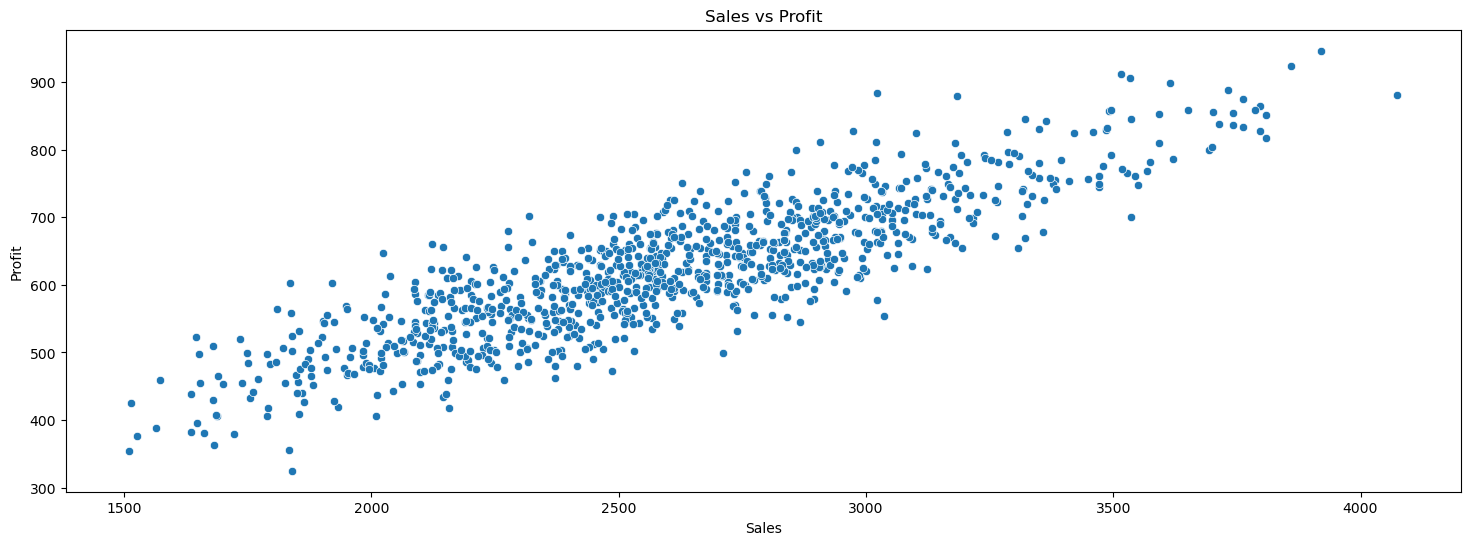

In [71]:
# Sales vs Profit - Scatter Plot (Two numerical variables).

fig, ax = plt.subplots(figsize=(18,6))

sns.scatterplot(x="Sales", y="Profit", data=df)
plt.title("Sales vs Profit")
plt.show()

### Insight: Sales vs Profit

- Strong positive correlation: The scatter plot shows a clear positive linear relationship between sales and profit. As sales increase, profit generally increases.
- Consistent profitability: Most data points cluster around the upward trend, suggesting that higher sales are consistently associated with higher profits.
- High-performing transactions: Sales above approximately $3,500 generally generate profits between $700 and $950.
- Profit variations: Some transactions with similar sales values generate different profit levels, potentially reflecting differences in product costs, discounts or profit margins.

Overall Insight: Sales and profit demonstrate a strong positive relationship, indicating that higher sales values are generally associated with greater profitability. However, the variation in profit at similar sales levels suggests that revenue alone does not fully explain profit performance.

Recommendation: Investigate profit margins across product categories, discount levels and regions to identify which transactions generate the highest returns relative to sales.

Note: Since profit is calculated as revenue minus cost, a positive relationship is expected. Analysing profit margin (%) would provide a clearer picture of profitability efficiency.

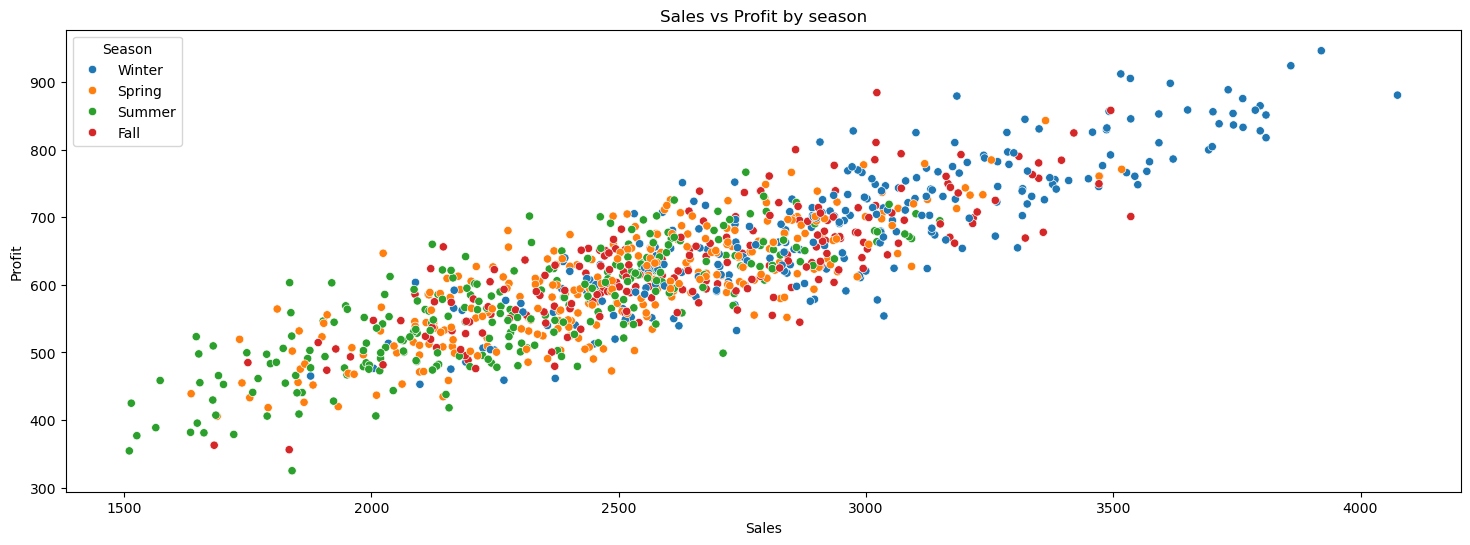

In [72]:
# Sales vs Profits by Season
fig, ax = plt.subplots(figsize=(18,6))

sns.scatterplot(x="Sales", y="Profit", data=df, hue="Season")
plt.title("Sales vs Profit by season")
plt.show()

### Insight: Sales vs Profit by Season

- Strong positive relationship: Sales and profit show a clear positive correlation across all four seasons, indicating that higher sales are generally associated with higher profits.
- Winter leads in performance: Winter records the highest sales and profit values, with some observations exceeding $3,500 in sales and $900 in profit.
- Summer shows weaker performance: Summer observations are more concentrated at lower sales and profit levels, with some sales around $1,500 generating profits below $400.
- Spring and Fall show moderate performance: Both seasons have considerable overlap, with most observations concentrated around $2,000–$3,100 in sales and $450–$750 in profit.
- Consistent relationship across seasons: Despite differences in sales levels, all seasons follow a similar upward pattern, suggesting that the relationship between sales and profit is broadly consistent throughout the year.

Overall Insight: Winter generally records stronger sales and higher profits, while summer tends to show weaker performance. However, the overlapping distributions suggest that seasonal differences are more evident in transaction values than in the relationship between sales and profit.

Recommendation: Compare average profit margins and total sales by season to determine whether winter is genuinely more profitable or simply benefits from higher transaction values. Further investigation into seasonal discounts, customer activity and product demand could help explain these differences.

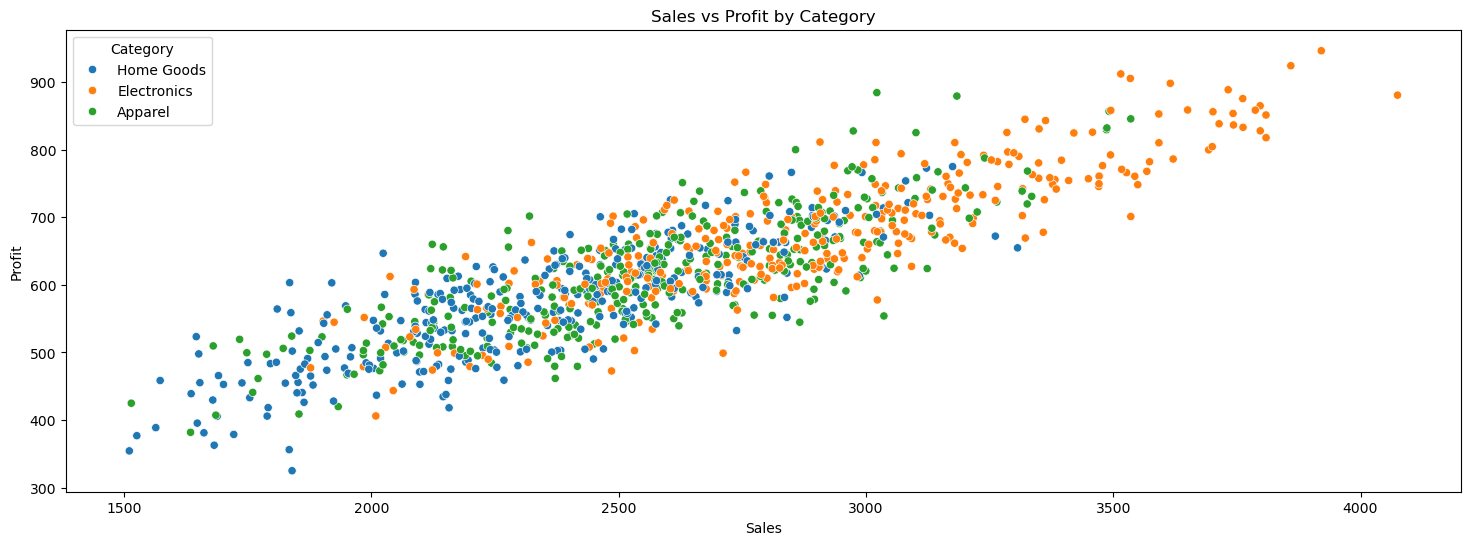

In [75]:
# Sales vs Profits by Category
fig, ax = plt.subplots(figsize=(18,6))

sns.scatterplot(x="Sales", y="Profit", data=df, hue="Category")
plt.title("Sales vs Profit by Category")
plt.show()

### Insight: Sales vs Profit by Product Category

- Strong positive relationship: All three product categories show a clear positive correlation between sales and profit, indicating that higher sales are generally associated with higher profits.
- Electronics leads in performance: Electronics records the highest sales and profit values, with some observations exceeding $3,500 in sales and $900 in profit.
- Home Goods shows lower performance: Home Goods observations are more concentrated at lower sales and profit levels, with some transactions generating less than $400 in profit.
- Apparel demonstrates moderate performance: Apparel generally falls between Home Goods and Electronics, although some transactions achieve relatively high profits despite moderate sales.
- Overlapping profitability: The three categories overlap considerably, suggesting that transactions with similar sales values can generate comparable profits regardless of product category.

Overall Insight: Electronics generally generates higher sales and profits, while Home Goods tends to record lower transaction values. However, the similar upward patterns across categories suggest that differences in absolute profitability may be largely associated with sales values rather than category-specific profit efficiency.

Recommendation: Compare profit margins, discount levels and average costs across product categories to determine whether Electronics genuinely delivers better profitability or simply generates higher-value sales.

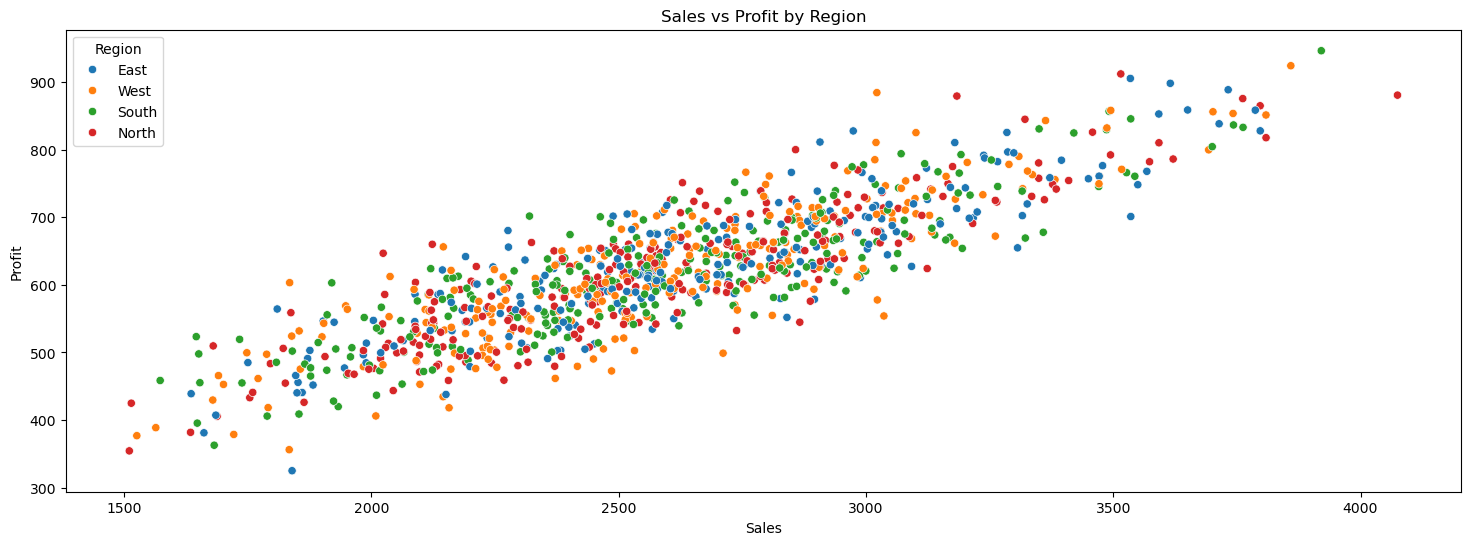

In [76]:
# Sales vs Profits by Region
fig, ax = plt.subplots(figsize=(18,6))

sns.scatterplot(x="Sales", y="Profit", data=df, hue="Region")
plt.title("Sales vs Profit by Region")
plt.show()

### Insight: Sales vs Profit by Region

- Strong positive relationship: All four regions show a clear positive correlation between sales and profit, indicating that higher sales are generally associated with higher profits.
- Similar regional performance: East, West, South and North follow nearly identical upward trends, suggesting a consistent relationship between sales and profitability across regions.
- High-performing transactions: All four regions record transactions exceeding $3,500 in sales and $800 in profit, demonstrating strong performance across different locations.
- Overlapping distributions: Data points from all regions overlap considerably, indicating that transactions with similar sales values tend to generate comparable profits regardless of region.
- Minor profitability variations: Some transactions generate different profit levels at similar sales values, potentially reflecting differences in operating costs, product categories or discounts.

Overall Insight: Sales and profit demonstrate a strong, consistent positive relationship across all four regions, with no clear regional advantage in the scatter plot. Although the East recorded slightly higher average sales and profit in the earlier regional analysis, the overall patterns remain remarkably similar.

Recommendation: Compare regional profit margins, discount levels and transaction volumes to identify meaningful differences in profitability and determine whether particular regions operate more efficiently than others.

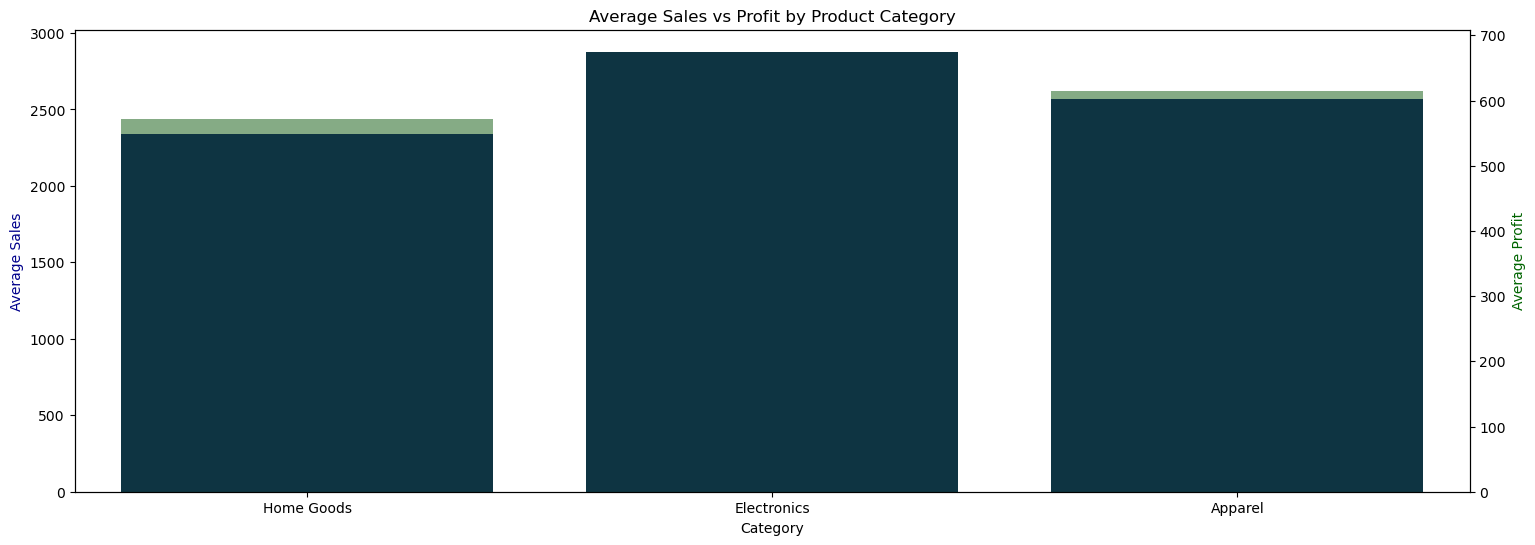

In [79]:
fig, ax = plt.subplots(figsize=(18, 6))

sns.barplot(
    x="Category",
    y="Sales",
    data=df,
    errorbar=None,
    color="darkblue",
    ax=ax
)

ax.set_ylabel("Average Sales", color="darkblue")

ax2 = ax.twinx()

sns.barplot(
    x="Category",
    y="Profit",
    data=df,
    color="darkgreen",
    errorbar=None,
    alpha=0.5,
    ax=ax2
)

ax2.set_ylabel("Average Profit", color="darkgreen")

plt.title("Average Sales vs Profit by Product Category")
plt.show()

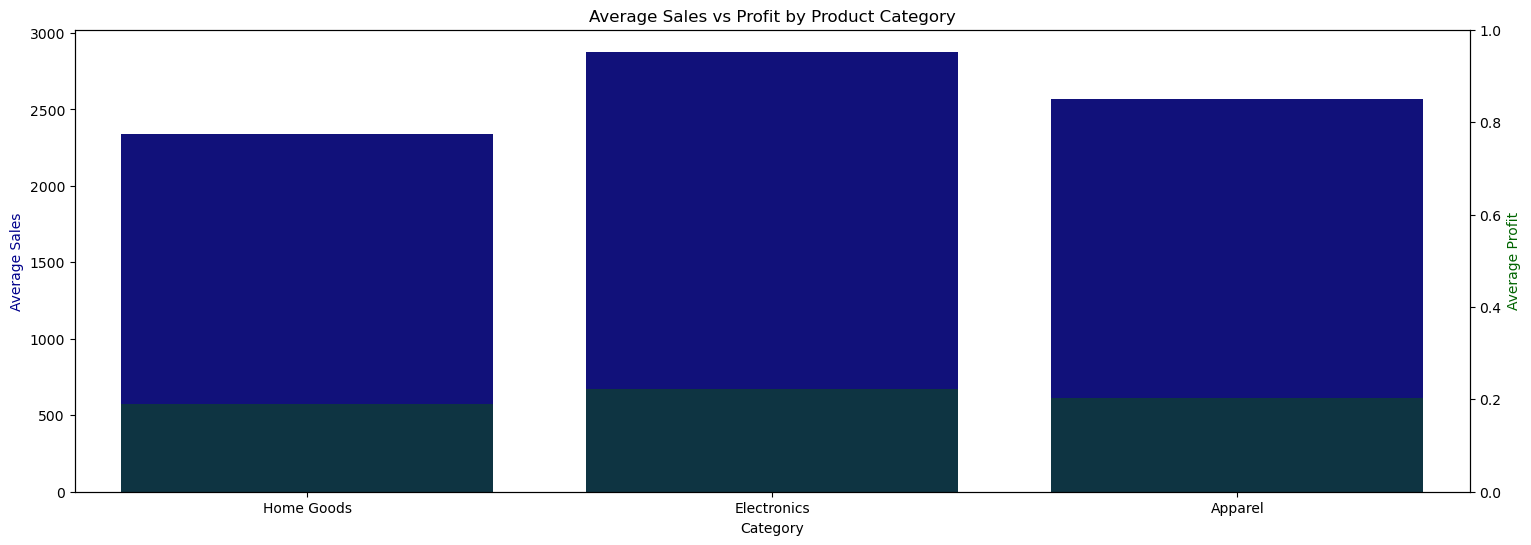

In [84]:
fig, ax = plt.subplots(figsize=(18, 6))

sns.barplot(
    x="Category",
    y="Sales",
    data=df,
    errorbar=None,
    color="darkblue",
    ax=ax
)

plt.ylabel("Average Sales", color="darkblue")

ax.twinx()

sns.barplot(
    x="Category",
    y="Profit",
    data=df,
    color="darkgreen",
    errorbar=None,
    alpha=0.5,
    ax=ax
)

plt.ylabel("Average Profit", color="darkgreen")

plt.title("Average Sales vs Profit by Product Category")
plt.show()

### Insight
- Electronics has the highest average sales (approximately $2,880) and profit (approximately $670).
- Apparel follows with average sales of approximately $2,570 and profit of $610.
- Home Goods has the lowest average sales (approximately $2,340) and profit (approximately $570).
Overall Insight: Electronics leads in both average sales and profit, while Home Goods records the lowest values. However, higher absolute profit does not necessarily mean a category has a higher profit margin.

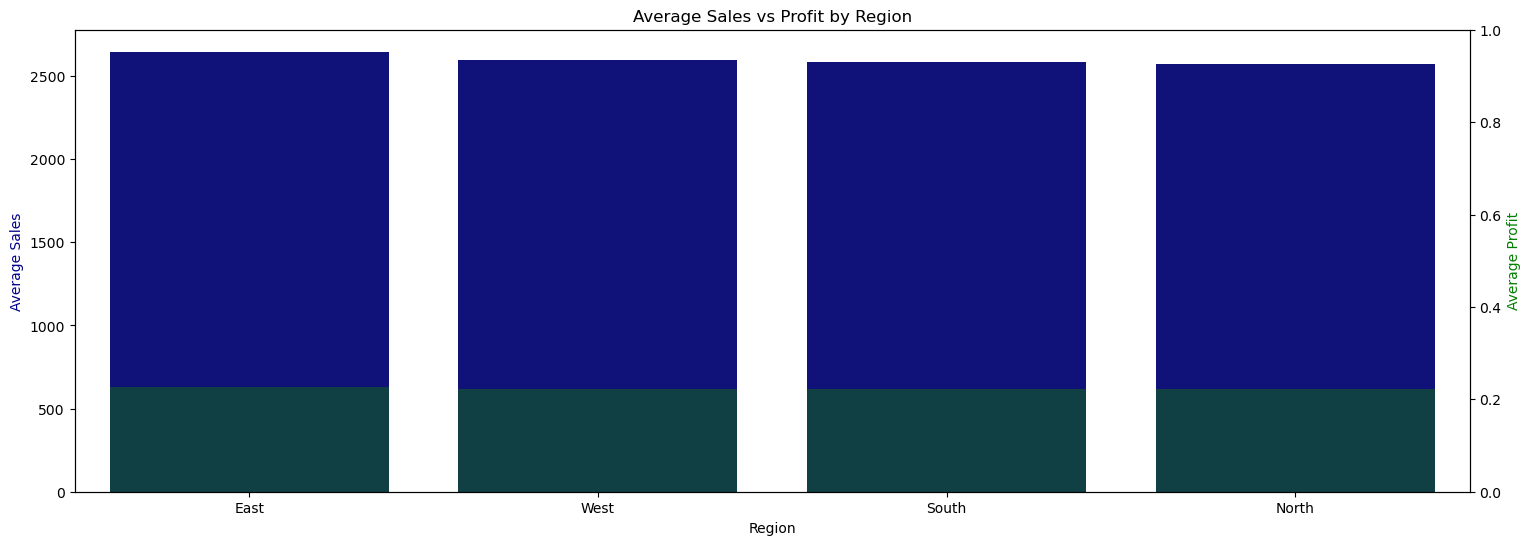

In [89]:
fig, ax = plt.subplots(figsize=(18, 6))

sns.barplot(
    x="Region",
    y="Sales",
    data=df,
    errorbar=None,
    color="darkblue",
    ax=ax
)

plt.ylabel("Average Sales", color="darkblue")

ax.twinx()

sns.barplot(
    x="Region",
    y="Profit",
    data=df,
    color="green",
    errorbar=None,
    alpha=0.5,
    ax=ax
)

plt.ylabel("Average Profit", color="green")

plt.title("Average Sales vs Profit by Region")
plt.show()

### Insight: Average Sales vs Profit by Region

- East leads in performance: The East records the highest average sales (approximately $2,650) and profit (approximately $635).
- West follows closely: Average sales are around $2,600, with profit approximately $620.
- South and North show similar performance: Both regions record average sales of approximately $2,580 and profits around $615.
- Small regional differences: Sales and profitability remain relatively consistent across all four regions, suggesting a balanced regional performance.

Overall Insight: The East performs slightly better in both average sales and profit, while the other regions show comparable results. This suggests that regional location may have a relatively limited association with average transaction performance.

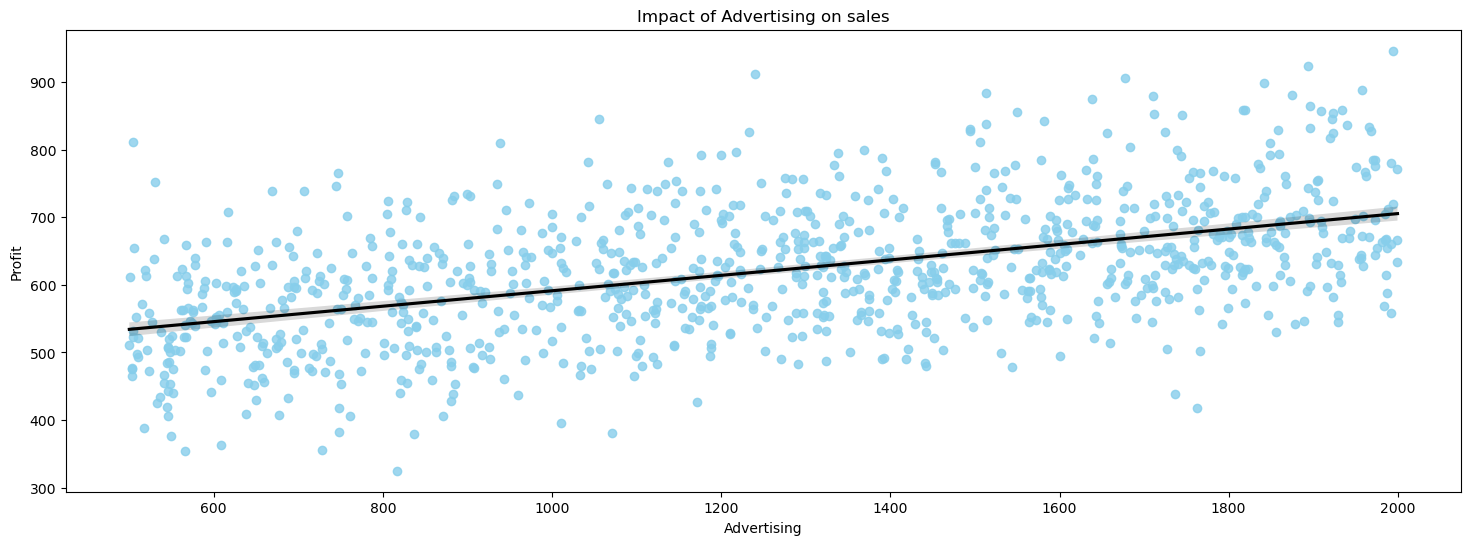

In [92]:
# Advertising impact on sales
plt.figure(figsize=(18,6))

sns.regplot(x="Advertising", y="Profit", data=df, color="skyblue", line_kws={"color": "black"})
plt.title("Impact of Advertising on sales")
plt.show()

### Higher advertising expenditure generally lead to higher sales. The correlation is positive

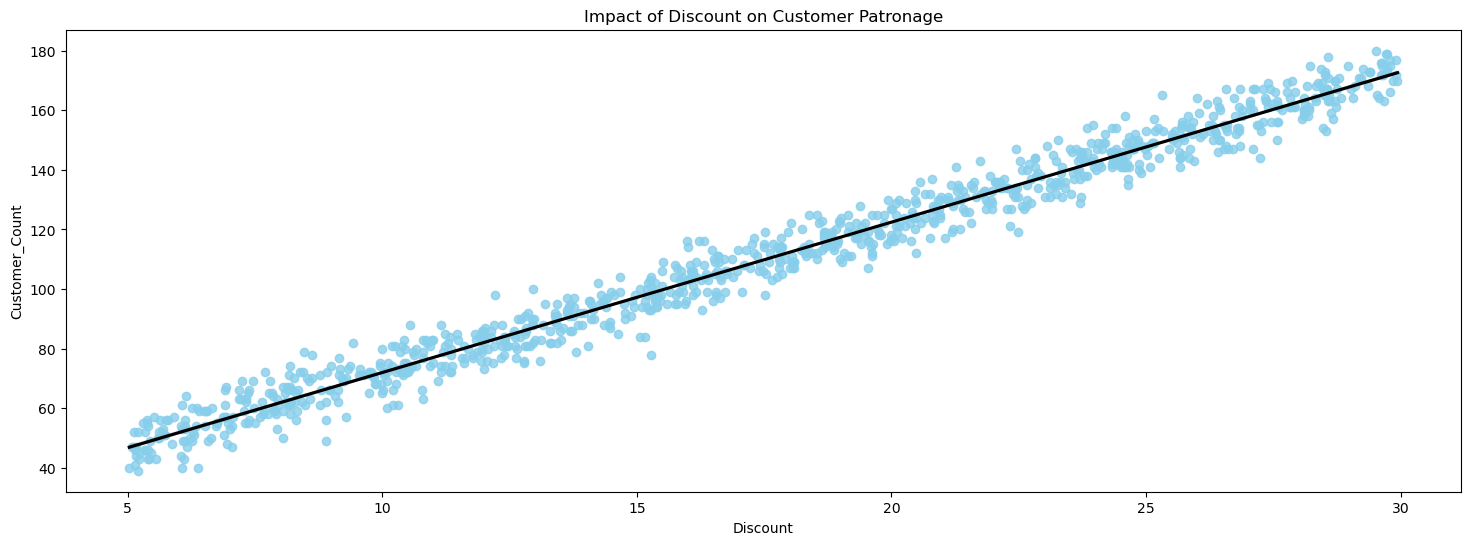

In [93]:
# Discount impact on customer patronage
plt.figure(figsize=(18,6))

sns.regplot(x="Discount", y="Customer_Count", data=df, color="skyblue", line_kws={"color": "black"})
plt.title("Impact of Discount on Customer Patronage")
plt.show()

#### Insight:
Strong correlation between discount and customer patronage. Higher discount attracts new and old customers

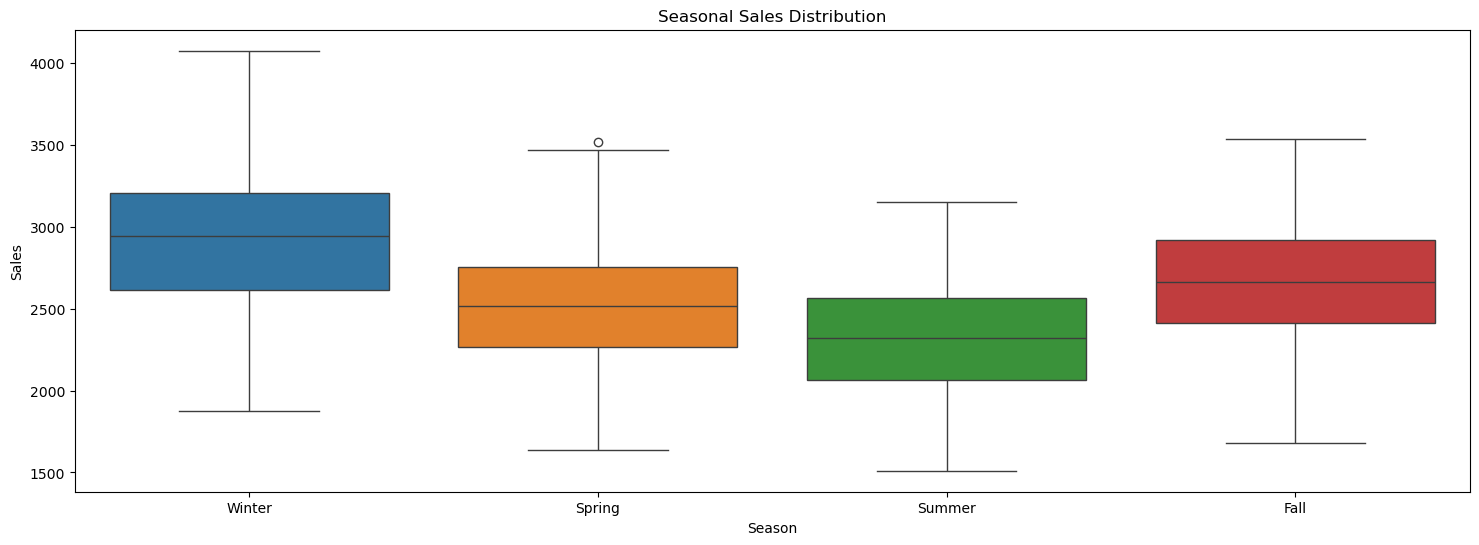

In [95]:
# Seasonal Sales Distribution
plt.figure(figsize=(18, 6))

sns.boxplot(
    x="Season",
    y="Sales",
    data=df,
    hue="Season"
    # errorbar=None,
    # color="darkblue",
    # ax=ax
)

plt.title("Seasonal Sales Distribution")
plt.show()

### Insight: 
Winter sees the highest sales, while summer the lowest

### Correlation Analysis on the Data

In [100]:
numeric_data = df.select_dtypes(include="number")
numeric_data

,Advertising,Discount,Year,Sales,Customer_Count,Profit
0,1275.18,15.74,2022,2679.56,95,652.90
1,1893.89,24.74,2022,3859.05,147,924.16
2,727.38,8.46,2022,2450.71,79,512.75
3,1757.23,15.37,2022,3056.75,97,624.60
4,1507.46,16.22,2022,2840.15,116,617.43
...,...,...,...,...,...,...
995,786.68,22.82,2024,2656.38,144,657.10
996,1798.73,17.82,2024,2994.30,114,624.29
997,936.72,29.62,2024,2516.03,176,560.81
998,1210.10,11.82,2024,2190.39,85,527.86


In [99]:
correlation_map = numeric_data.corr()
correlation_map

,Advertising,Discount,Year,Sales,Customer_Count,Profit
Advertising,1.000000,-0.041544,0.052870,0.596664,-0.032036,0.508804
Discount,-0.041544,1.000000,-0.021071,0.276811,0.989094,0.223716
Year,0.052870,-0.021071,1.000000,-0.021249,-0.037677,0.006903
Sales,0.596664,0.276811,-0.021249,1.000000,0.309698,0.861604
Customer_Count,-0.032036,0.989094,-0.037677,0.309698,1.000000,0.248441
Profit,0.508804,0.223716,0.006903,0.861604,0.248441,1.000000


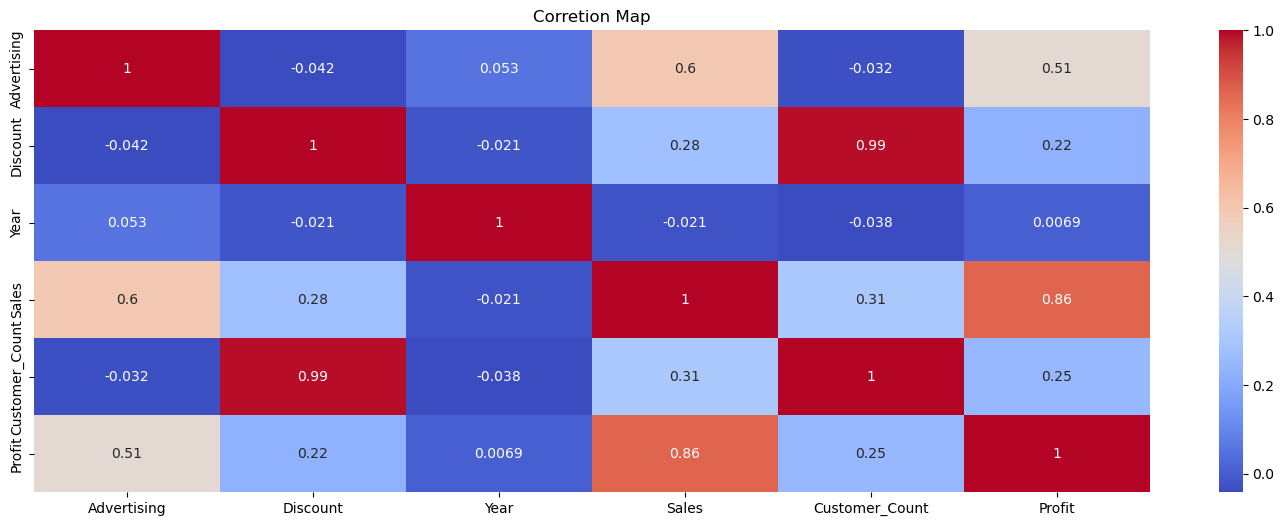

In [102]:
# Seasonal Sales Distribution
plt.figure(figsize=(18, 6))

sns.heatmap(
   correlation_map,
   annot=True,
   cmap="coolwarm"
)

plt.title("Corretion Map")
plt.show()

Minus(-): No correlation; Zero(0): Neutral; Positive(+) one(1): Strong correlation
### Advertising and Profit: Strong correlation
### Advertising and Customer_count: No correlation
### As Discount increases, Customer count increases: 0.99. strong correlation



### Overall Insight: Correlation Analysis

The correlation analysis reveals a strong positive relationship between Sales and Profit (0.86), indicating that higher sales are generally associated with increased profitability. Advertising also shows a moderate positive correlation with Sales (0.60) and Profit (0.51), suggesting that marketing investment may contribute to business performance.

Interestingly, Discount and Customer Count have an exceptionally strong positive correlation (0.99), indicating that higher discounts are closely associated with increased customer activity. However, discounts show weaker relationships with Sales (0.28) and Profit (0.22), suggesting that attracting more customers does not necessarily translate into proportional revenue or profit growth.

Recommendation: Focus on optimising advertising expenditure and discount strategies to increase sales while protecting profit margins. Further analysis should investigate whether discounts genuinely drive customer activity or whether the strong correlation reflects how the dataset was constructed.

Note: Correlation does not imply causation.
